## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Leonardo Gonzalez Oliveros & Daniel Sebastian Castillo baquero" # @param {"type":"string"}
carnet = 1000116657    -   1000116730

## 1) Descripción del problema **[1 pts]**

Una plataforma de red social desea analizar las conexiones de amistad entre sus usuarios, cada usuario sera representado por un vertice y cada amistad mediante una arista. 
El objetivo principal es implementar recorridos DFS y BFS, ademas de emplear BFS para encontrar conexiones de amistad en la menor cantidad de saltos.

Teniendo encuenta los siguientes usuarios como usuarios parte de una red inicial.

→ Ana
→ Carlos
→ Laura
→ Mateo
→ Sofia
→ Daniel
→ Valentin

## 2) Requerimientos **[2 pts]**


RQFO1: El sistema debe generar una lista de adyacencia teniendo en cuenta la red principal. Debe mostrar cada usuario junto con sus conexiones directas.

RQFO2: El sistema debe realizar una busqueda en anchura (BFS) mediante una cola. Debe mostrar el orden de visita y el nivel de cada usuario respecto del usuario de inicio.

RQFO3: El sistema debe realizar una busqueda en profundidad (DFS) mediante una pila o recursividad, avanzando por cada conexion de amistad hasta que no pueda continuar y luego retrocediendo. Debe mostrar el orden en que visita los usuarios.

RQFO4: El sistema debe permitir que el usuario ingrese una otro usuario inicial y ejecutar BFS y DFS desde ella. Debe mostrar ambos recorridos y para BFS el nivel de cada usuario. Si el usuario no existe, se debe informar el error.

RQFO5: El sistema debe permitir que el usuario ingrese los usuarios de inicio y destino y buscar una conexion de amistad con el menor numero de conexiones mediante BFS. Debe mostrar la conexion de amistad encontrada y la cantidad de conexiones. Si no existe una conexion de amistad, se debe informarlo.

RQFO6: El sistema debe permitir registrar una usuario nuevo y conectarlo con dos usuarios existentes. Despues de agregarlo, debe mostrar la lista de adyacencia actualizada. Si la usuario o alguna conexion no es valida, se debe informar el error.



**Requerimientos NO funcionales**

**Eficiencia:** BFS, DFS y busqueda de conexion deben recorrer el grafo en tiempo O(V + E), donde V es el numero de usuarios y E el de conexiones.

**Funcionalidad:** Cada operacion debe aceptar entradas validas y producir la salida que es correspondiente (Lista de conexiones, usuarios, niveles y amistades) 

**Correccion:** Una usuario debe visitarse una sola vez por recorrido, BFS debe encontrar una conexion con el minimo numero de conexiones, las conexiones deben ser bidireccionales y no duplicarse.

**Mantenibilidad:** La representacion del grafo y las busquedas de BFS, DFS y validacion se deben organizar en funciones separadas, para facilitar cambios y correciones.



## 3) Historias de usuario **[2 pts]**
Como usuario, quiero elegir una opcio n para visualizar desde la red de amistades inicial o los usuarios ingresados.
CA:
- La eleccio n debe ser un numero entero. Si no corresponde a una opcio n valida, se muestra un mensaje informativo y se solicita nuevamente.


Como usuario, quiero visualizar la red de amistades mediante una lista de adyacencia que muestre todas las usuarios y sus amistades.
CA:
- Se deben respetar las conexiones entre usuarios. Si un usuario no estaconectado con otra amistad, se debe mostrar que no existe esa conexio n.


Como usuario, quiero visualizar los recorridos BFS y DFS teniendo en cuenta la red de amistades basica e inicial.
CA:
- El recorrido BFS se debe mostrar mediante una cola e indicar el nivel de cada usuario.
- El recorrido DFS se debe mostrar mediante una pila y visualizar el recorrido maximo antes de llegar al final.


Como usuario, quiero ingresar una usuario inicial para realizar los recorridos y encontrar la conexion mas corta entre dos usuarios. Finalmente quiero visualizar los recorridos BFS y DFS y la conexion mas corta, respectivamente.
CA:
- El usuario inicial debe existir en la red de amistades. Si no existe, se muestra un mensaje informativo y se permite ingresarlo nuevamente.
- Los usuarios para encontrar la conexion mas corta deben existir en la red de amistades. Si alguna no existe, se muestra un mensaje informativo y se permite ingresarlas nuevamente.


Como usuario, quiero registrar una usuario nuevo y conectarlo con otras dos usuarios existentes. Despus de actualizar la red de amistades, quiero visualizar los dos recorridos y buscar nuevamente una conexion entre dos usuarios.
CA:
- La usuario nueva no debe existir previamente. Los dos usuarios de conexio n deben existir en la red de amistades y ser diferentes entre si y del usuario nuevo.


## 4) Diagramas de flujo **[5 pts]**


En el diagrama de flujo se visuliza cada una de las opciones se ve representadas por cuadros azules, seis puntos que el usuario puede realizar, los procesos se conectan con flechas continuas, mientras que cuando un condicional resulta en NO la accion se representa con una linea punteada.

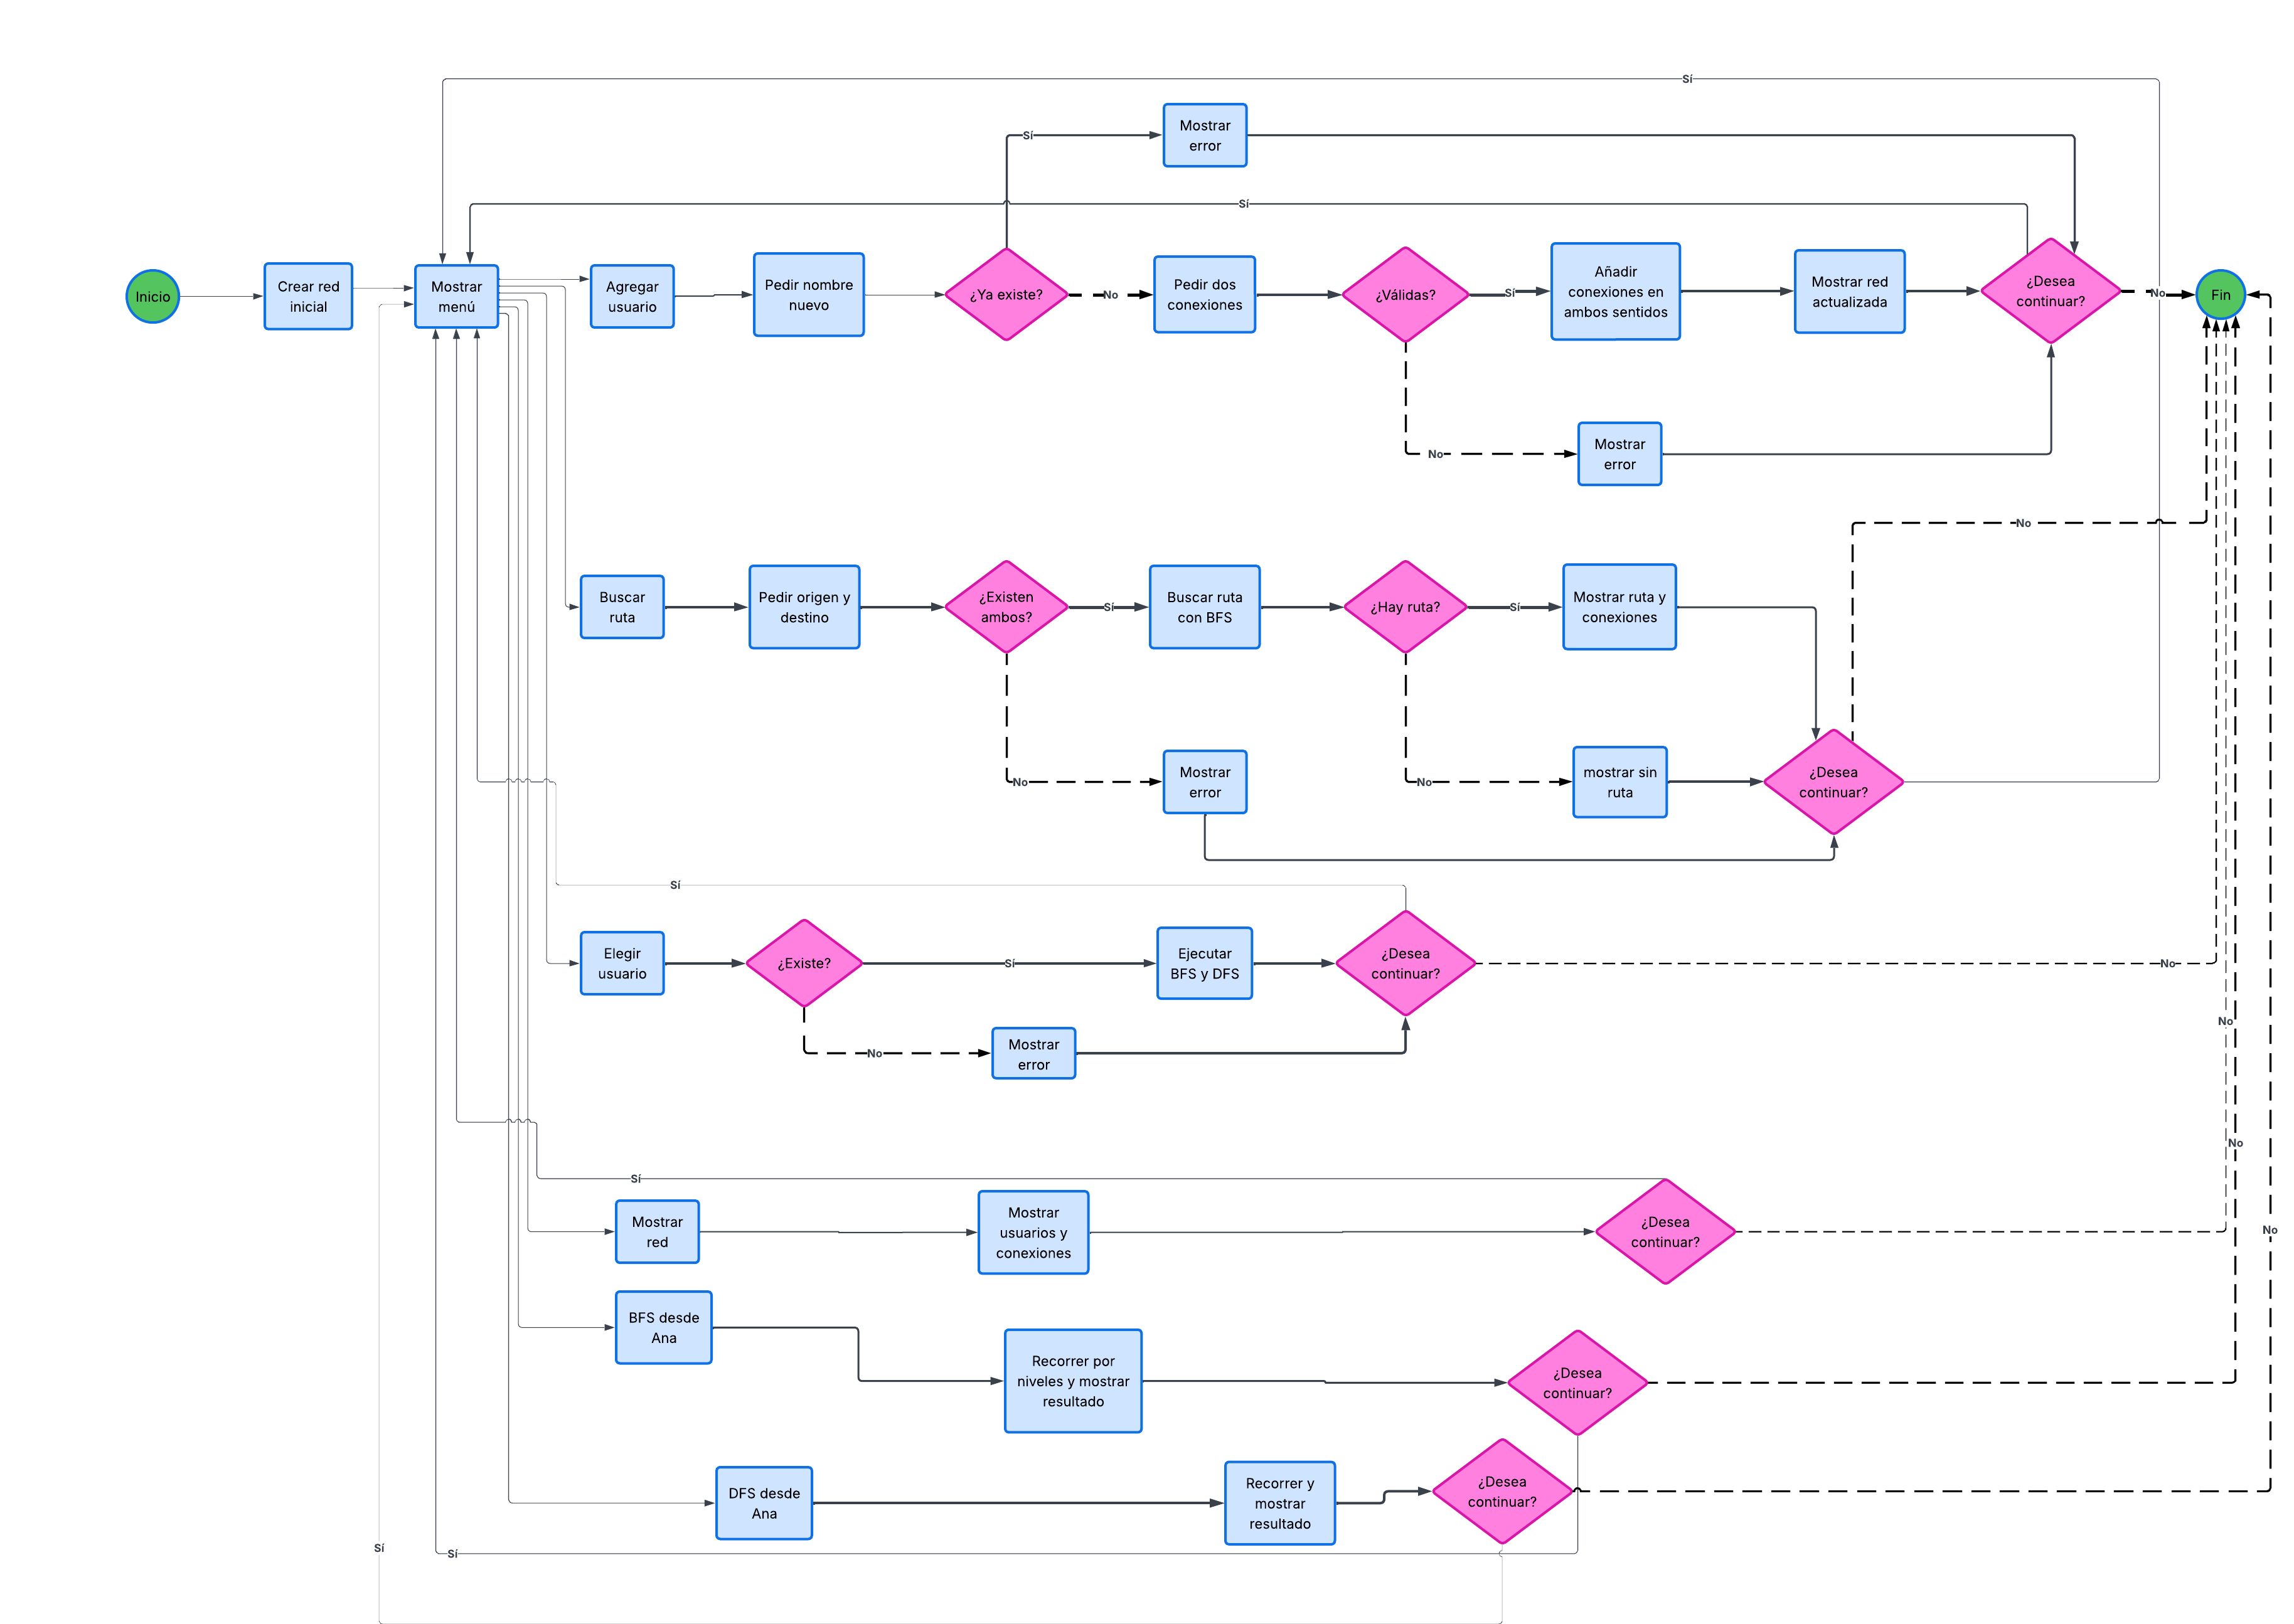


### 5) Análisis de complejidad **[15 pts]**
Tomando **V** como la cantidad de usuarios y **E** la cantidad de amistades, con lista de adyacencia, BFS y DFS visitan cada usuario que se puede llegar una vez y revisan sus amistades: **T(V,E) = c₁V + c₂E**, por lo tanto su tiempo es **O(V + E)**. Guardar la red final requiere **O(V + E)** espacio. Para la busqueda de ruta BFS tiene el mismo peor caso, **O(V + E)**, si origen y destino son iguales termina en **O(1)**.
 
f(x)=x

 
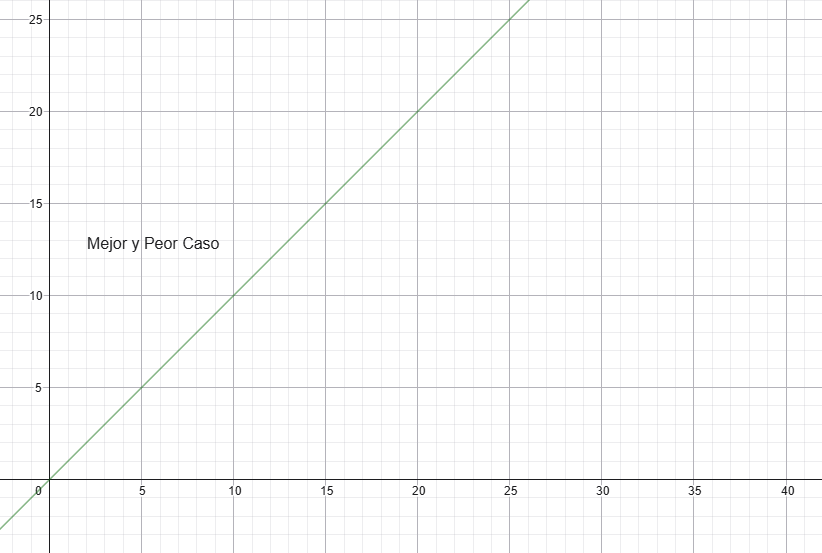


## 6) Código funcional **[15 pts]**



In [ ]:
red = {
    "Ana": ["Carlos", "Laura"], "Carlos": ["Ana", "Mateo", "Sofia"],"Laura": ["Ana", "Daniel"],}

red2 = {"Ana": ["Carlos", "Laura"], "Carlos": ["Ana", "Mateo", "Sofia"], "Laura": ["Ana", "Daniel"], 
        "Mateo": ["Carlos"],"Sofia": ["Carlos", "Valentina"],"Daniel": ["Laura", "Valentina"],"Valentina": ["Sofia", "Daniel"],}


def mostrar(red):
    for usu in red:
        print(usu, ":", ", ".join(red[usu]))


def bfs(red, ini):
    cola = [(ini, 0)]
    visitadas = []

    while cola:
        usu, nivel = cola.pop(0)

        if usu not in visitadas:
            visitadas.append(usu)
            print(usu, "nivel:", nivel)

            for amistad in red[usu]:
                if amistad not in visitadas:
                    cola.append((amistad, nivel + 1))


def dfs(red, usu, visitadas):
    visitadas.append(usu)
    print(usu, end="")

    for amistad in red[usu]:
        if amistad not in visitadas:
            print(" -> ", end="")
            dfs(red, amistad, visitadas)


def busconex(red, ini, fin):
    cola = [[ini]]
    visitadas = [ini]

    while cola:
        ruta = cola.pop(0)
        usu = ruta[-1]

        if usu == fin:
            return ruta

        for amistad in red[usu]:
            if amistad not in visitadas:
                visitadas.append(amistad)
                cola.append(ruta + [amistad])

    return None


def agregar_usuario(red, nueva, conexiones):
    if not nueva:
        print("Tiene que haber nombre")
        return False

    if nueva in red:
        print("Este usuario ya existe")
        return False

    if len(conexiones) < 2:
        print("Debes conectarlo con al menos dos usuarios")
        return False

    for conexion in conexiones:
        if conexion not in red:
            print("El usuario", conexion, "no existe en la red")
            return False

    red[nueva] = []
    for conexion in conexiones:
        if conexion not in red[nueva]:
            red[nueva].append(conexion)
        if nueva not in red[conexion]:
            red[conexion].append(nueva)

    return True


def leer_usu(mensaje, red):
    while True:
        usu = input(mensaje).strip().title()
        if usu in red:
            return usu
        print("El usuario no existe, intentelo de nuevo")


def main():
    while True:
        print("------------------------------- ELECCION -------------------------------")
        print("1) Visualizacion lista de adyacencia")
        print("2) Visualizacion BFS desde Ana")
        print("3) Visualizacion DFS desde Ana")
        print("4) Elegir usuario de ini para BFS y DFS")
        print("5) Buscar la ruta mas corta entre dos usuarios")
        print("6) Agregar una usuario nueva")

        try:
            eleccion = int(input("Ingrese el numero correspondiente a su eleccion: "))
        except ValueError:
            print("Debe ingresar un numero entero del 1 al 6")
            continue

        if eleccion == 1:
            mostrar(red2)

        elif eleccion == 2:
            bfs(red2, "Ana")

        elif eleccion == 3:
            dfs(red2, "Ana", [])
            print()

        elif eleccion == 4:
            ini = leer_usu("Ingrese el usuario inicial: ", red2)
            print("Recorrido BFS desde", ini, ":")
            bfs(red2, ini)
            print("-----------------------------------------------------------------------")
            print("Recorrido DFS desde", ini, ":")
            dfs(red2, ini, [])
            print()

        elif eleccion == 5:
            ini = leer_usu(" Usuario de inicio: ", red2)
            fin = leer_usu(" Usuario de destino: ", red2)
            ruta = busconex(red2, ini, fin)

            if ruta is not None:
                print("Ruta encontrada:")
                print(" -> ".join(ruta))
                print("Cantidad de conexiones:", len(ruta) - 1)
            else:
                print("No existe.")

        elif eleccion == 6:
            nueva = input("Nuevo usuario: ").strip().title()
            conexiones = []

            while len(conexiones) < 2:
                conexion = leer_usu("Conectar con una usuario existente: ", red2)
                if conexion in conexiones:
                    print("Ya ingresaste esa conexion, escoja otra")
                else:
                    conexiones.append(conexion)

            if agregar_usuario(red2, nueva, conexiones):
                print("Usuario agregado. red actualizada:")
                mostrar(red2)

                print("BFS desde Ana:")
                bfs(red2, "Ana")

                print("DFS desde Ana:")
                dfs(red2, "Ana", [])
                print()

                ini = leer_usu(" Usuario de inicio para buscar una ruta: ", red2)
                fin = leer_usu(" Usuario de destino: ", red2)
                ruta = busconex(red2, ini, fin)

                if ruta is not None:
                    print("Ruta encontrada:")
                    print(" -> ".join(ruta))
                    print("Cantidad de conexiones:", len(ruta) - 1)
                else:
                    print("No existe una ruta entre esos usuarios")

        else:
            print("Opcion no valida. Elija un numero del 1 al 6")

main()

## 7) Tests aplicados **[15 pts]**

Las funciones se ejecutan en base a la eleccion realizada por el usuario, por lo que no es logico sustituir valores de una funcion si no hay una opcion prviamente escogida.



 
Elección = 1
Salida= Ana : Carlos, Laura
Carlos : Ana, Mateo, Sofia
Laura : Ana, Daniel
Mateo : Carlos
Sofia : Carlos, Valentina
Daniel : Laura, Valentina
Valentina : Sofia, Daniel
 


Elección 2:
Salida=Ana nivel: 0
Carlos nivel: 1
Laura nivel: 1
Mateo nivel: 2
 


Elección = 3
Salida = Ana -> Carlos -> Mateo -> Sofia -> Valentina -> Daniel -> Laura
 


Elección = 4
Usu ini = Carlos
Salida = Recorrido DFS desde Carlos :
Carlos -> Ana -> Laura -> Daniel -> Valentina -> Sofia -> Mateo
 


Elección = 5
Usu 1 = Daniel
Usu 2 = Carlos
Salida = Daniel -> Laura -> Ana -> Carlos
Cantidad de conexiones: 3
 

 
Elección = 6
Usu nuevo = Isabella
Conexion = Ana
Salida = Conexion hecha
 